<!-- d2l:prose id=mlp-implementation-md-1 fw=all -->

# Implementation

In that section, we hand-crafted the weights of a two-unit ReLU network to solve XOR. Now let us let minibatch SGD learn hidden features directly from Fashion-MNIST images. Inserting a single hidden layer of $h = 256$ ReLU units between the $d = 784$ input pixels and the $q = 10$ class logits multiplies our parameter count and per-image FLOPs 26-fold ($203{,}530$ parameters vs. $7{,}850$ for softmax regression).

In this section, we implement this two-layer MLP both from scratch (`MLPScratch`) and concisely (`MLP`) using framework `Sequential` containers, verify our untrained network with three quick pre-training sanity checks, compare its learning curve and GPU epoch time head-to-head against softmax regression, and look at the weight patterns that the hidden units learn in $\mathbf{W}^{(1)}$.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import time

<!-- d2l:prose id=mlp-implementation-md-2 fw=all -->

## Implementation from Scratch

### The Parameters and Forward Pass

Flattening each $28 \times 28$ image to $d = 784$ features, a one-hidden-layer MLP with $h = 256$ hidden units and $q = 10$ outputs (the figure) allocates four parameter tensors:

$$\mathbf{W}^{(1)} \in \mathbb{R}^{784 \times 256}, \quad \mathbf{b}^{(1)} \in \mathbb{R}^{256}, \quad \mathbf{W}^{(2)} \in \mathbb{R}^{256 \times 10}, \quad \mathbf{b}^{(2)} \in \mathbb{R}^{10}.$$

![Architecture of our Fashion-MNIST MLP: a minibatch of $n$ images is flattened to $n \times 784$, mapped through an affine layer and ReLU to an $n \times 256$ hidden representation $\mathbf{H}$, and projected to $n \times 10$ class logits $\mathbf{O}$.](../img/mdl-mlp-arch.svg)

To keep our head-to-head comparison with softmax regression controlled, we initialize both weight matrices from $\mathcal{N}(0, 0.01^2)$ and both biases to $0$ (in that section, we will see why random initialization is mandatory to break symmetry between hidden units, and how He initialization improves upon `std=0.01`):

In [3]:
class MLPScratch(d2l.Classifier):
    """An MLP with one hidden layer, implemented from scratch."""
    def __init__(self, num_inputs, num_outputs, num_hiddens, lr, std=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W1 = nn.Parameter(d2l.normal(0, std, (num_inputs, num_hiddens)))
        self.b1 = nn.Parameter(d2l.zeros(num_hiddens))
        self.W2 = nn.Parameter(d2l.normal(0, std, (num_hiddens, num_outputs)))
        self.b2 = nn.Parameter(d2l.zeros(num_outputs))

<!-- d2l:prose id=mlp-implementation-md-3 fw=all -->

Next, we implement the elementwise activation `relu(X)` from scratch by multiplying `X` with the Boolean mask `X > 0` so positive entries pass through unchanged and negative entries become zero:

In [4]:
def relu(X):
    return X * (X > 0)

<!-- d2l:prose id=mlp-implementation-md-4 fw=all -->

We then factor the hidden layer into `hidden(self, X)`—which flattens each image minibatch to `(-1, self.num_inputs)` and computes $\mathbf{H} = \mathrm{relu}(\mathbf{X}\mathbf{W}^{(1)} + \mathbf{b}^{(1)})$—so `forward(self, X)` simply returns the raw class logits $\mathbf{O} = \mathbf{H}\mathbf{W}^{(2)} + \mathbf{b}^{(2)}$ (consumed directly by `Classifier.loss`):

In [5]:
@d2l.add_to_class(MLPScratch)
def hidden(self, X):
    X = d2l.reshape(X, (-1, self.num_inputs))  # One flattened image per row
    return relu(d2l.matmul(X, self.W1) + self.b1)

@d2l.add_to_class(MLPScratch)
def forward(self, X):
    return d2l.matmul(self.hidden(X), self.W2) + self.b2  # The logits

<!-- d2l:prose id=mlp-implementation-md-5 fw=all -->

### Checks before Training

Before launching a long training run, passing a tiny 8-image slice through the *untrained* network verifies three invariants in milliseconds:

1. **Shapes:** `H` has shape `(8, 256)` and `O` has shape `(8, 10)`.
2. **Initial loss:** Near-zero weights produce near-zero logits ($\hat{y}_j \approx 1/10$), so the initial cross-entropy loss sits right near $\log 10 \approx 2.303$.
3. **Active ReLU fraction:** With zero biases and symmetric weights, roughly $50\%$ of hidden pre-activations are positive.

In [6]:
data = d2l.FashionMNIST(batch_size=256)
model = MLPScratch(num_inputs=784, num_outputs=10, num_hiddens=256, lr=0.1)
X, y = next(iter(data.train_dataloader()))
X, y = X[:8], y[:8]  # Eight images suffice for the checks
H, O = model.hidden(X), model(X)
active = d2l.reduce_mean(d2l.astype(H > 0, d2l.float32))
print('H:', H.shape, 'O:', O.shape)
print(f'loss {d2l.numpy(model.loss(O, y)):.3f}, '
      f'fraction of active units {d2l.numpy(active):.2f}')

H: torch.Size([8, 256]) O: torch.Size([8, 10])
loss 2.303, fraction of active units 0.53


<!-- d2l:prose id=mlp-implementation-md-6 fw=all -->

### Training

Now we train `MLPScratch` for $30$ epochs on Fashion-MNIST with minibatch size $256$ and learning rate $\eta = 0.1$ (passing `num_gpus=1` so `Trainer` uses a GPU when available):

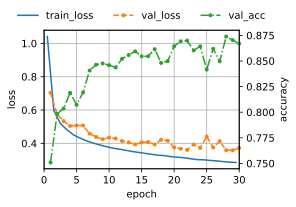

In [7]:
trainer = d2l.Trainer(max_epochs=30, num_gpus=1)
trainer.fit(model, data)

<!-- d2l:prose id=mlp-implementation-md-7 fw=all -->

## Concise Implementation

Using each framework's `Sequential` container and built-in linear and ReLU layers, we can express the exact same architecture in a few lines without manual parameter arrays (initializing weights from $\mathcal{N}(0, 0.01^2)$ and biases to $0$ to match `MLPScratch`):

In [8]:
class MLP(d2l.Classifier):
    """An MLP with one hidden layer, built from framework layers."""
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.LazyLinear(num_hiddens),
                                 nn.ReLU(), nn.LazyLinear(num_outputs))

    def weight_init(self, module):
        # The Trainer calls this once the lazy layers know their shapes
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, std=0.01)
            nn.init.zeros_(module.bias)

<!-- d2l:prose id=mlp-implementation-md-8 fw=all -->

## Comparison with Softmax Regression

### Accuracy

Let us train both the concise `MLP` and `d2l.SoftmaxRegression` for $30$ epochs under identical settings, recording each model's average wall-clock time per epoch in `seconds` and its validation accuracy trajectory in `curves`:

In [9]:
curves, seconds = {'MLP from scratch': trainer.history['val_acc']}, {}
trainer.board.display = False
models = {'concise MLP': MLP(num_outputs=10, num_hiddens=256, lr=0.1),
          'softmax regression': d2l.SoftmaxRegression(num_outputs=10, lr=0.1)}
for name, net in models.items():
    start = time.perf_counter()
    trainer.fit(net, data)
    seconds[name] = (time.perf_counter() - start) / trainer.max_epochs
    curves[name] = trainer.history['val_acc']

<!-- d2l:prose id=mlp-implementation-md-9 fw=all -->

Plotting all three validation accuracy histories in `curves` across epochs 1 to 30 compares our scratch and concise MLPs directly against the linear softmax baseline:

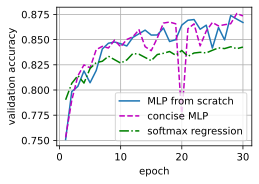

In [10]:
d2l.plot(list(range(1, trainer.max_epochs + 1)), list(curves.values()),
         'epoch', 'validation accuracy', legend=list(curves))

<!-- d2l:prose id=mlp-implementation-md-10 fw=all -->

To smooth out single-epoch validation fluctuations, we print each model's mean validation accuracy over the final five epochs (`acc[-5:]`) alongside the training-set accuracy of `MLPScratch`:

In [11]:
print('validation accuracy averaged over the last 5 epochs')
for name, acc in curves.items():  # A single epoch can land a few points low
    print(f'  {name}: {sum(acc[-5:]) / 5:.3f}')
train_acc = trainer.evaluate(model, data, train=True)['acc']
print(f'training accuracy of the MLP from scratch: {train_acc:.3f}')

validation accuracy averaged over the last 5 epochs
  MLP from scratch: 0.865
  concise MLP: 0.869
  softmax regression: 0.842


training accuracy of the MLP from scratch: 0.890


<!-- d2l:prose id=mlp-implementation-md-11 fw=all -->

Notice two instructive patterns in the learning curves:

1. **Slow warmup from `std=0.01`:** On epoch 1, both MLPs actually trail softmax regression! Because both $\mathbf{W}^{(1)}$ and $\mathbf{W}^{(2)}$ start with entries around $0.01$, the hidden activations $\mathbf{H}$ and the backpropagated gradients into $\mathbf{W}^{(1)}$ are suppressed by a factor of $0.01$ until $\mathbf{W}^{(2)}$ grows—a bottleneck we eliminate with He initialization in that section.
2. **Cutting a fifth of the classification errors:** By epochs 26–30, softmax regression plateaus around $84\%$ validation accuracy ($16\%$ error rate), whereas both MLPs reach $\sim 87\%$ validation accuracy ($\sim 13\%$ error rate, and $87$–$90\%$ training accuracy)—eliminating roughly $20\%$ of softmax regression's mistakes.

Which mistakes are left? In that section we saw that the four upper-body tops (T-shirt, pullover, coat, and shirt) look alike, so they are the natural suspects. For each of the two models we just trained, we count the validation errors and how many of them mistake one top for another:

In [12]:
tops = [0, 2, 4, 6]  # T-shirt/top, pullover, coat, shirt
for name, net in models.items():
    errors = among_tops = 0
    for batch in data.val_dataloader():
        X, y = trainer.prepare_batch(batch)
        pred, y = d2l.numpy(net(X)).argmax(axis=1), d2l.numpy(y)
        errors += (pred != y).sum()
        among_tops += ((pred != y) & np.isin(y, tops) & np.isin(pred, tops)).sum()
    print(f'{name}: {errors} errors, {among_tops} of them between two tops')

concise MLP: 1265 errors, 799 of them between two tops


softmax regression: 1574 errors, 915 of them between two tops


<!-- d2l:prose id=mlp-implementation-md-12 fw=all -->

For both models, more than half of all errors confuse two tops. The MLP makes fewer such errors than softmax regression does, but the tops remain the hard part of Fashion-MNIST.

### The Learned Features

In that section, the 10 columns of softmax regression's weight matrix $\mathbf{W}$ had to act as whole-garment templates. To see what our MLP's 256 hidden units learned, we first copy its trained weight matrices $\mathbf{W}^{(1)} \in \mathbb{R}^{784 \times 256}$ and $\mathbf{W}^{(2)} \in \mathbb{R}^{256 \times 10}$ into NumPy arrays `W1` and `W2`:

In [13]:
W1, W2 = d2l.numpy(model.W1), d2l.numpy(model.W2)

<!-- d2l:prose id=mlp-implementation-md-13 fw=all -->

We then select the 10 hidden units `units` whose columns in `W1` have the largest Euclidean norms, reshape each 784-vector into a $28 \times 28$ image normalized to $[-1, 1]$, and title each unit by the garment class to which `W2` assigns its largest positive outgoing weight (`W2[units].argmax(1)`):

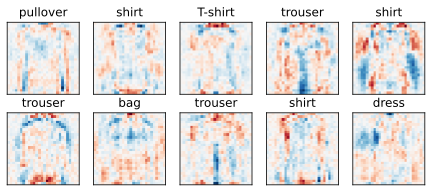

In [14]:
names = data.text_labels(range(10))
units = np.argsort(np.linalg.norm(W1, axis=0))[::-1][:10]  # Largest weights
images = W1[:, units].T.reshape(10, 28, 28)
images /= np.abs(images).max(axis=(1, 2), keepdims=True)  # Own color scale
d2l.show_images(images, 2, 5, titles=[names[k] for k in W2[units].argmax(1)],
                cmap='RdBu_r', vmin=-1, vmax=1);

<!-- d2l:prose id=mlp-implementation-md-14 fw=all -->

These images do not look like whole-garment templates. Each high-norm hidden unit weighs some regions of the image positively (red) and neighboring regions negatively (blue), so it responds to a **contrast**: bright pixels in one region together with dark pixels next to it, for instance along the shoulders or down the sides of the torso. Most of the patterns still extend over much of the garment, so we should not read them as small edge detectors. The output layer forms its ten scores by combining $256$ such contrasts.

### Parameters, Computation, and Time

| Model | Parameters | Multiply-adds / image | Validation accuracy (epochs 26–30) |
|:--|--:|--:|--:|
| Softmax regression | $7{,}850$ | $7{,}840$ | $\sim 84\%$ |
| MLP ($h = 256$ ReLU units) | $203{,}530$ | $203{,}264$ | $\sim 87\%$ |

Even though our MLP performs 26 times as many multiply-adds per image as softmax regression, let us compare their wall-clock times per epoch:

In [15]:
for name, s in seconds.items():
    print(f'{name}: {s:.1f} s per epoch')

concise MLP: 2.4 s per epoch
softmax regression: 2.5 s per epoch


<!-- d2l:prose id=mlp-implementation-md-15 fw=all -->

On modern hardware (especially a GPU), both models take almost the exact same wall-clock time per epoch! At width $h = 256$, data loading and Python/kernel launch overhead dominate the runtime, so the 26-fold increase in dense matrix arithmetic runs virtually for free (Exercise 3 explores the width at which matrix arithmetic finally overtakes data-loading overhead).

## Summary

- **Pre-training checks:** A single forward pass on a small batch before training verifies tensor shapes, confirms that the initial cross-entropy loss sits near $\log q \approx 2.30$, and checks that roughly half of ReLU hidden units activate.
- **Empirical gain over linear classification:** Adding one 256-unit ReLU hidden layer lifts Fashion-MNIST validation accuracy from $\sim 84\%$ to $\sim 87\%$ (cutting error rate by nearly a fifth) at virtually identical per-epoch wall-clock time. The hidden units learn contrast patterns (bright in one region, dark in a neighboring one) in place of whole-garment templates.

## Exercises

1. [code] **A hidden layer without activation.** Replace `relu` by the
   identity in `MLPScratch` and train the resulting model as in this
   section.
    1. Compare its validation accuracy after 30 epochs with that of the MLP
       and of softmax regression.
    1. After training, compute $\mathbf{W} = \mathbf{W}^{(1)}\mathbf{W}^{(2)}$
       and $\mathbf{b} = \mathbf{W}^{(2)\top}\mathbf{b}^{(1)} + \mathbf{b}^{(2)}$,
       and verify on a minibatch that $\mathbf{X}\mathbf{W} + \mathbf{b}$
       reproduces the logits of the model.
    1. Exercise 1 showed that such a network
       computes exactly the affine maps whose weight matrix has rank at most
       the hidden width. Explain why this restriction costs nothing here,
       and state below which hidden width it would reduce what the model
       can represent on Fashion-MNIST.

1. [code] **Single hidden unit.** Set `num_hiddens=1` in `MLPScratch`, so
   that its hidden layer has a single ReLU unit with weights
   $\mathbf{w}^{(1)} \in \mathbb{R}^{784 \times 1}$ and bias
   $b^{(1)} \in \mathbb{R}$. Each input $\mathbf{x} \in \mathbb{R}^{1 \times 784}$
   is then reduced to the scalar
   $t = \operatorname{ReLU}(\mathbf{x}\mathbf{w}^{(1)} + b^{(1)}) \geq 0$,
   and the logits are $\mathbf{o} = t\, \mathbf{w}^{(2)} + \mathbf{b}^{(2)}$
   with $\mathbf{w}^{(2)} \in \mathbb{R}^{1 \times 10}$ and
   $\mathbf{b}^{(2)} \in \mathbb{R}^{10}$.
    1. Show that each class is predicted on at most one interval of $t$, and
       that the order of these intervals along the $t$ axis is fixed by the
       entries of $\mathbf{w}^{(2)}$. Describe the regions of input space
       that the model assigns to the classes, and state what they imply for
       separating the ten Fashion-MNIST classes.
    1. Suppose that after some update
       $\mathbf{x}\mathbf{w}^{(1)} + b^{(1)} < 0$ for every training
       example. Which parameters receive nonzero gradients from then on, and
       what does the network predict? Why does the same event do little
       harm when it hits one of the 256 hidden units of this section?
    1. Train the model five times, and report for each run the validation
       accuracy and the fraction of validation examples on which $t > 0$,
       which `model.hidden` gives you. Compare any run in which this
       fraction is zero with your answer to (b).
1. [code] **Width.** Train `MLP` as in this section, for 30 epochs at
   learning rate 0.1, with hidden widths
   $h \in \{16, 64, 256, 1024, 4096\}$, and record the final validation
   accuracy and the time per epoch.
    1. Plot both against $h$ on a logarithmic axis. Beyond which width does
       the accuracy stop improving by more than its variation from epoch to
       epoch?
    1. The multiply-adds grow in proportion to $h$. Time one pass over the
       training data that only reads the minibatches, without any model,
       and use it to explain the part of the time curve that does not grow
       with $h$. From which width on does the arithmetic dominate on your
       hardware?
    1. Repeat the training at widths 64 and 1024 with learning rates
       $\{0.03, 0.1, 0.3\}$. Does the best learning rate depend on the
       width?

<!-- d2l:prose id=mlp-implementation-md-16 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/93)